  CASO PRÁCTICO: ¿CÓMO INTERPRETA UNA INTELIGENCIA ARTIFICIAL UN DÍGITO ESCRITO A MANO?
¡Bienvenido/a! En este caso práctico aprenderás cómo la visión por computadora y la
inteligencia artificial utilizan el álgebra lineal para interpretar imágenes.

¿QUÉ QUEREMOS PREDECIR?
Queremos que nuestra computadora reciba una imagen de un número escrito a mano 
(del 0 al 9) y nos diga con precisión qué número es.

¿QUÉ PAPEL TIENEN LAS MATRICES?
Para una computadora, una imagen no es más que una cuadrícula de números. Cada píxel 
tiene un valor numérico que representa su brillo. Esta cuadrícula es, matemáticamente,
una MATRIZ.

OBJETIVOS DE APRENDIZAJE:
1. Comprender que una imagen digital se representa y manipula como una matriz.
2. Aplicar operaciones matriciales básicas (normalización, transposición, escala, traslación).
3. Entender los filtros locales (convolución/correlación cruzada) como herramientas de extracción de características.
4. Comprender cómo un clasificador de IA utiliza el pro

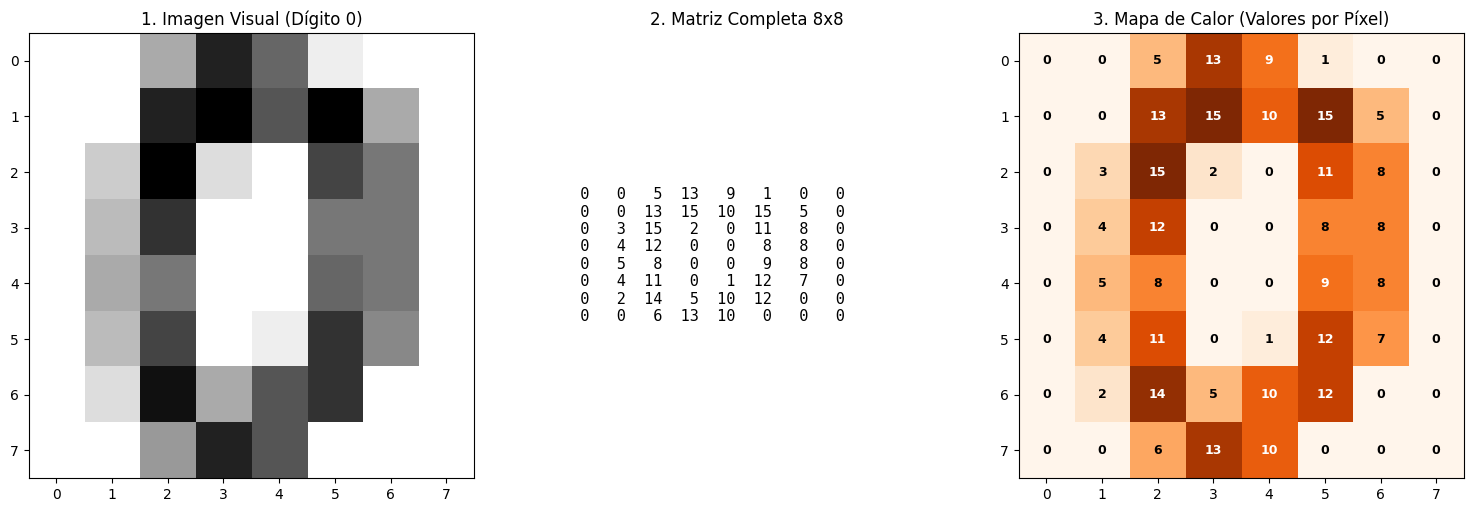

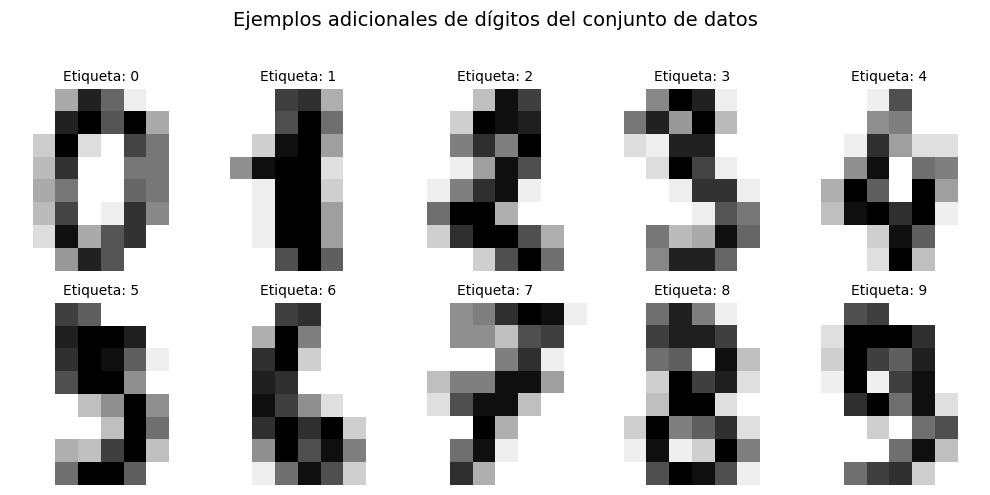

--------------------------------------------------------------------------------
INTERPRETACIÓN DOCENTE:
Como puedes observar en el mapa de calor, los valores más altos (hasta 15 o 16, tonos oscuros)
se concentran en los bordes y el contorno del círculo, dibujando el número '0'.
Las posiciones con valor 0 representan el fondo blanco donde no hay trazo.
--------------------------------------------------------------------------------

3. OPERACIONES MATRICIALES SOBRE LA IMAGEN


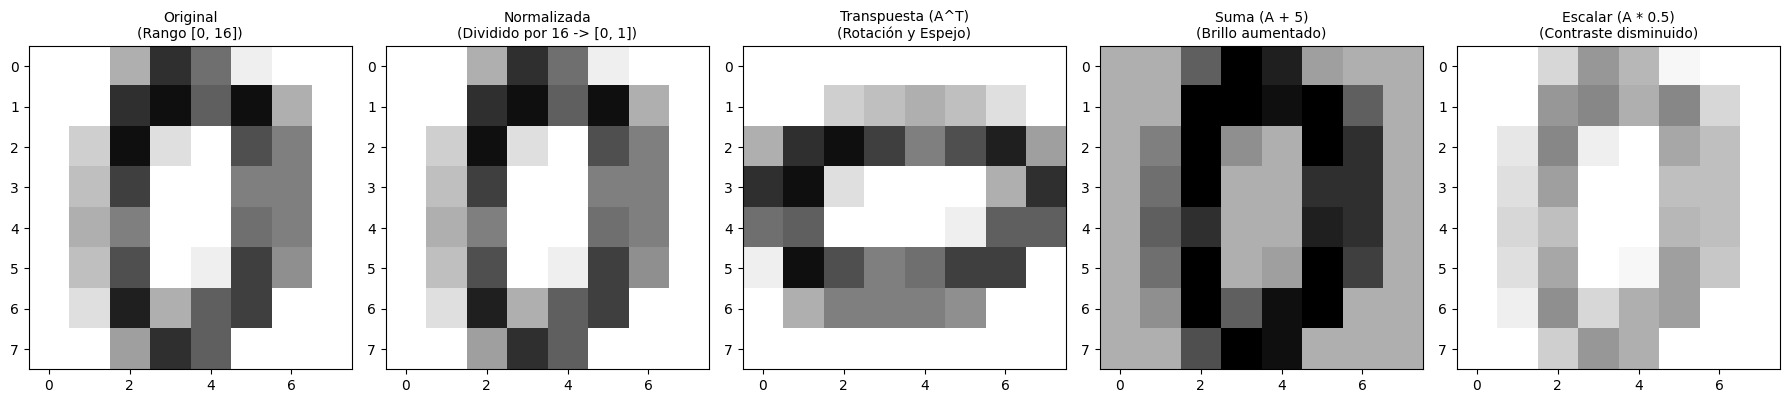

--------------------------------------------------------------------------------
EXPLICACIÓN MATEMÁTICA Y EFECTO VISUAL:
- Normalización: Mantiene la misma estructura de la imagen pero escala los valores al intervalo [0, 1].
  Es crucial para evitar problemas de inestabilidad numérica en la IA.
- Transposición (A^T): Intercambia la fila 'i' por la columna 'i'. Visualmente equivale a reflejar la imagen respecto a su diagonal principal.
- Suma de un escalar: Al sumar 5 a cada celda, aumentamos la intensidad general del fondo y del dígito (mayor brillo).
  ¡Ojo! Los valores calculados exceden el límite máximo de 16 (por ejemplo, 16 + 5 = 21). Para visualizarlo correctamente
  sin distorsiones de color, 'recortamos' (clipping) los valores para que se mantengan en el intervalo [0, 16].
- Multiplicación por un escalar: Al multiplicar por 0.5, reducimos la amplitud de las diferencias tonales a la mitad,
  generando una imagen más tenue y con menos contraste.
----------------------------------

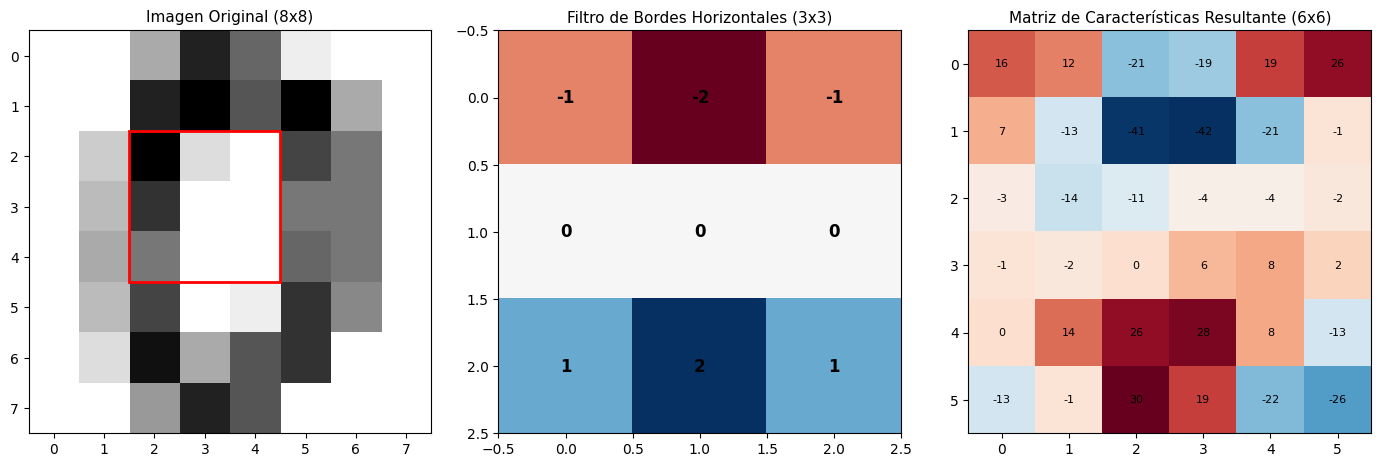

--------------------------------------------------------------------------------
INTERPRETACIÓN DEL FILTRADO:
La matriz resultante de 6x6 resalta los bordes horizontales. Los valores fuertemente positivos (azul oscuro)
o negativos (rojo oscuro) marcan las transiciones donde el trazo del número cambia abruptamente.
Nota: Esta es una extracción de características clásica en visión artificial, independiente del clasificador
que entrenaremos a continuación, el cual usará la imagen normalizada directamente de forma lineal.
--------------------------------------------------------------------------------

5. DE UNA IMAGEN DE DOS DIMENSIONES A UN VECTOR
Matriz original de la imagen (Dimensiones): (8, 8)
Vector plano resultante (Dimensiones): (64,)
Representación del vector de 64 posiciones obtenido a partir de la imagen:
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11. 

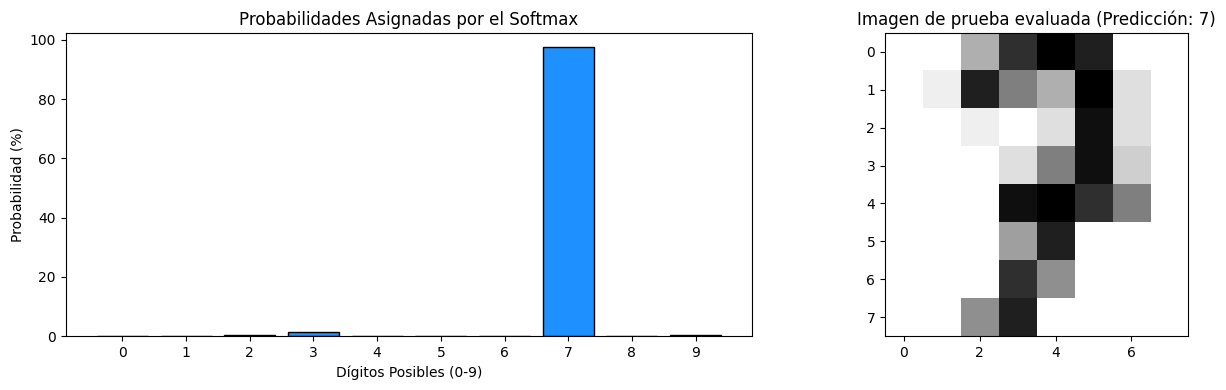

--------------------------------------------------------------------------------
EXPLICACIÓN DOCENTE:
- Cada fila en la matriz de pesos W actúa como un 'detector' de patrones para una clase específica.
- El sesgo b aporta una inclinación o ajuste a priori para cada dígito antes de ver la imagen.
- La multiplicación matricial condensa este conocimiento y calcula una puntuación para cada clase.
- Softmax distribuye estos valores de manera exponencial para que sumen exactamente 100%,
  permitiéndonos interpretar los resultados como probabilidades reales del sistema de IA.
--------------------------------------------------------------------------------

8. EVALUACIÓN GLOBAL DEL MODELO E INTERPRETACIÓN DE PESOS
Exactitud (Accuracy) global en datos de prueba: 96.67%

Matriz de Confusión:
[[53  0  0  0  1  0  0  0  0  0]
 [ 0 51  0  1  0  1  1  0  1  0]
 [ 0  0 53  0  0  0  0  0  0  0]
 [ 0  1  0 54  0  0  0  0  0  0]
 [ 0  0  0  0 53  0  0  0  1  0]
 [ 0  0  0  0  0 53  0  0  0  2]
 [ 0  1  

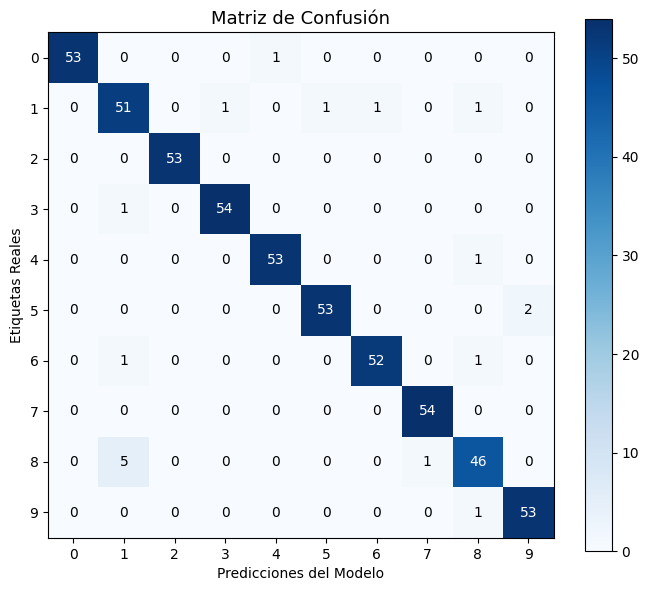


¿CÓMO LEER LA MATRIZ DE CONFUSIÓN?
Las filas representan las etiquetas reales de las imágenes y las columnas las predicciones realizadas.
La diagonal principal de izquierda a derecha muestra los aciertos del modelo.
Cualquier número fuera de la diagonal representa una confusión; por ejemplo, si en la fila '3' y columna '8'
hay un '1', significa que una imagen real de un '3' fue clasificada erróneamente como un '8'.



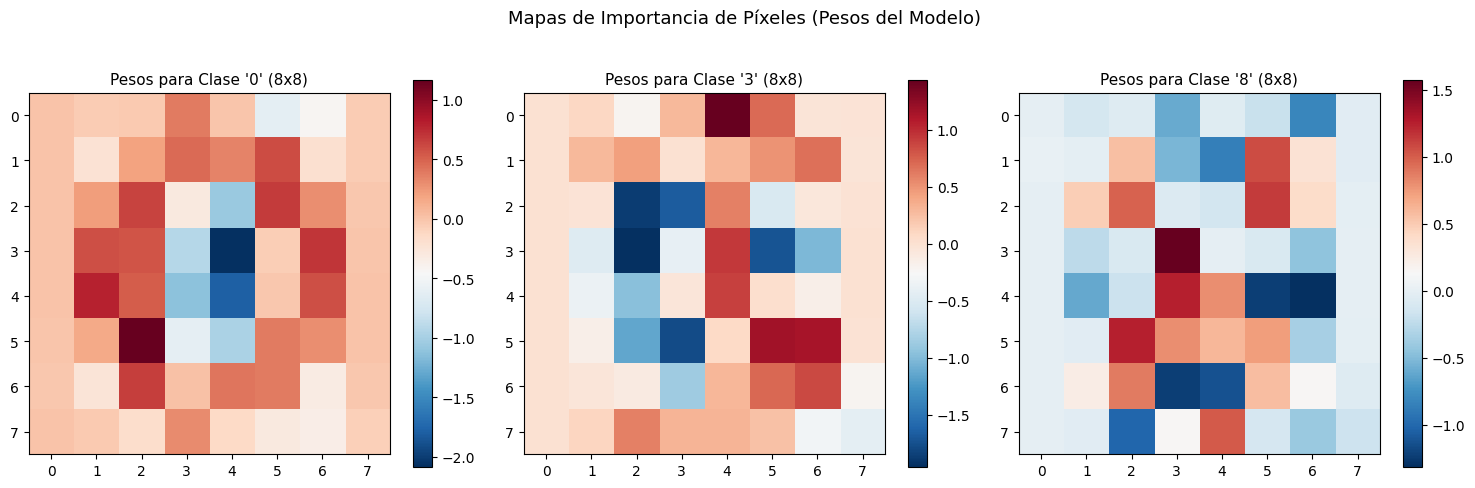

--------------------------------------------------------------------------------
INTERPRETACIÓN DE LOS MAPAS DE PESOS:
- Pesos Positivos (Rojo intenso): Zonas donde la presencia de trazo negro incrementa la posibilidad
  de pertenecer a este dígito. Para el '0', nota que el centro tiene pesos negativos (azul), indicando que
  si el centro tiene trazos oscuros, NO es un '0', mientras que el contorno circular tiene pesos fuertemente positivos.
- Pesos Negativos (Azul intenso): Zonas que contradicen o descartan la presencia de dicho dígito.
--------------------------------------------------------------------------------

9. EXPERIMENTACIÓN GUIADA Y EJERCICIOS PRÁCTICOS
--- EJERCICIO 1: MODIFICAR PÍXELES CLAVE
Instrucciones: Tomaremos un dígito '0' real y pintaremos artificialmente su centro
de color negro (valor máximo 16) para observar si el modelo se confunde.



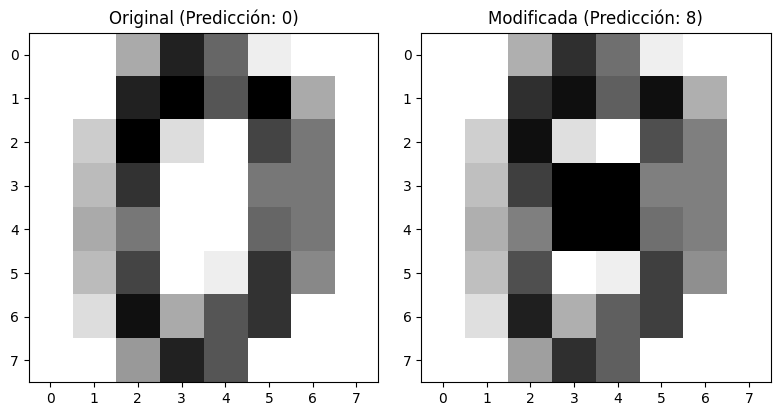

Resultado del Ejercicio 1: El modelo ahora interpreta la imagen modificada como un: 8
Pregunta de interpretación: ¿Por qué cambió la predicción del modelo al rellenar el centro?
Solución: Al rellenar el centro del '0', se activaron los pesos negativos de la clase '0' ubicados en esa zona central, disminuyendo drásticamente su probabilidad y forzando al modelo a predecir otra clase que típicamente tiene trazo central.

--- EJERCICIO 2: ADICIÓN DE RUIDO ALEATORIO CONTROLADO
Instrucciones: Añadiremos ruido aleatorio Gaussiano de forma controlada a una imagen
y evaluaremos cómo afecta la confianza del modelo.



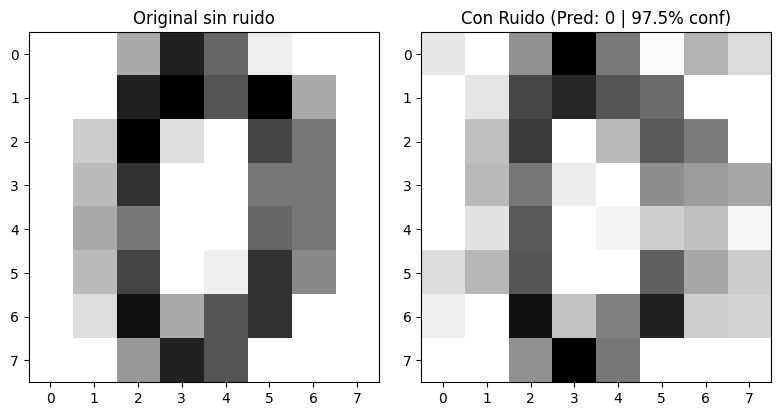

Pregunta de interpretación: ¿Sigue siendo correcta la predicción? ¿Qué pasó con el porcentaje de probabilidad?
Solución: El modelo conserva la predicción correcta debido a su robustez, pero la probabilidad asignada a la clase correcta disminuye, reflejando una menor certeza debida a las perturbaciones en los píxeles.

--- EJERCICIO 3: DIBUJAR UN DÍGITO DESDE CERO
Instrucciones: Definiremos manualmente un dígito '1' o '4' utilizando una matriz de NumPy 8x8.



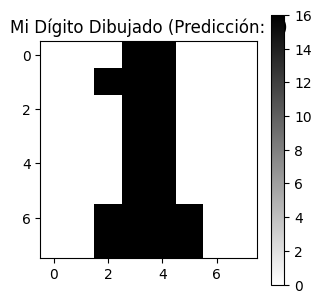

Resultado del Ejercicio 3: El modelo clasificó tu dígito dibujado como un: 2
Aclaración: Un dígito creado a mano de forma rígida y simétrica puede presentar diferencias menores con respecto al estilo y la suavidad de las muestras de entrenamiento reales del dataset, pero el modelo típicamente logra detectarlo con éxito.

10. RESUMEN Y CIERRE DIDÁCTICO DEL CASO
TABLA RESUMEN DE ELEMENTOS MATEMÁTICOS DEL CASO PRÁCTICO:

+----------------------+---------------------------+-------------+----------------------------------------------+
| Objeto del Caso      | Representación Matemática | Dimensiones | Función en el sistema de Inteligencia        |
+----------------------+---------------------------+-------------+----------------------------------------------+
| Imagen de entrada    | Matriz A                  | 8 x 8       | Cuadrícula con intensidad de brillo de píxel |
| Filtro Local         | Matriz F                  | 3 x 3       | Extractor de características (bordes)        |
| Vector

In [ ]:
"""
CASO PRÁCTICO GUIADO: ¿Cómo interpreta una IA un dígito escrito a mano?
Rol: Docente de Álgebra Lineal y Especialista en Inteligencia Artificial
Idioma: Español
"""

# =============================================================================
# 1. PRESENTACIÓN DEL PROBLEMA (TEXTO EXPLICATIVO)
# =============================================================================

print("""================================================================================
  CASO PRÁCTICO: ¿CÓMO INTERPRETA UNA INTELIGENCIA ARTIFICIAL UN DÍGITO ESCRITO A MANO?
================================================================================
¡Bienvenido/a! En este caso práctico aprenderás cómo la visión por computadora y la
inteligencia artificial utilizan el álgebra lineal para interpretar imágenes.

¿QUÉ QUEREMOS PREDECIR?
Queremos que nuestra computadora reciba una imagen de un número escrito a mano
(del 0 al 9) y nos diga con precisión qué número es.

¿QUÉ PAPEL TIENEN LAS MATRICES?
Para una computadora, una imagen no es más que una cuadrícula de números. Cada píxel
tiene un valor numérico que representa su brillo. Esta cuadrícula es, matemáticamente,
una MATRIZ.

OBJETIVOS DE APRENDIZAJE:
1. Comprender que una imagen digital se representa y manipula como una matriz.
2. Aplicar operaciones matriciales básicas (normalización, transposición, escala, traslación).
3. Entender los filtros locales (convolución/correlación cruzada) como herramientas de extracción de características.
4. Comprender cómo un clasificador de IA utiliza el producto punto y la multiplicación matricial para predecir.
5. Implementar el paso matemático hacia adelante (Forward Pass) con NumPy y Softmax.

REPASO RÁPIDO DE ÁLGEBRA LINEAL:
- MATRIZ: Un arreglo bidimensional de números ordenados en filas y columnas.
- DIMENSIÓN: El tamaño de la matriz, expresado como (filas x columnas). Una imagen de 8x8 píxeles es una matriz de dimensión 8x8.
- ELEMENTO A[i, j]: El valor numérico ubicado en la fila 'i' y la columna 'j'. En una imagen, representa la intensidad del color en ese píxel exacto.
================================================================================
""")

# =============================================================================
# 2. UNA IMAGEN ES UNA MATRIZ (CARGA Y VISUALIZACIÓN DE DATOS)
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

print("\n--- Cargar el dataset load_digits de scikit-learn ---")
digits = load_digits()

# Seleccionamos la primera imagen del dataset como ejemplo principal (un número '0')
indice_ejemplo = 0
imagen_original = digits.images[indice_ejemplo]
etiqueta_real = digits.target[indice_ejemplo]

print(f"Se ha cargado una imagen de ejemplo que representa el dígito: {etiqueta_real}")
print(f"Dimensión de la matriz de la imagen: {imagen_original.shape} (8 filas por 8 columnas)")
print(f"Rango real de intensidad del dataset: Mínimo = {imagen_original.min()}, Máximo = {imagen_original.max()}")
print("Nota: En este dataset, 0 representa color blanco de fondo y 16 representa el negro más intenso (escala de grises invertida).")

# Visualización múltiple de la imagen
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Imagen en escala de grises estándar
axes[0].imshow(imagen_original, cmap='gray_r', interpolation='nearest')
axes[0].set_title(f"1. Imagen Visual (Dígito {etiqueta_real})", fontsize=12)
axes[0].axis('on')

# 2. Matriz numérica impresa textualmente
axes[1].axis('off')
axes[1].set_title("2. Matriz Completa 8x8", fontsize=12)
matriz_texto = "\n".join([" ".join([f"{val:3.0f}" for val in fila]) for fila in imagen_original])
axes[1].text(0.1, 0.5, matriz_texto, family='monospace', fontsize=11, va='center', ha='left')

# 3. Mapa de calor con valores anotados
im_heat = axes[2].imshow(imagen_original, cmap='Oranges', interpolation='nearest')
axes[2].set_title("3. Mapa de Calor (Valores por Píxel)", fontsize=12)
for i in range(8):
    for j in range(8):
        val_pixel = imagen_original[i, j]
        color_texto = 'white' if val_pixel > 8 else 'black'
        axes[2].text(j, i, f"{val_pixel:.0f}", ha='center', va='center', color=color_texto, fontsize=9, weight='bold')

plt.tight_layout()
plt.show()

# Mostrar varias imágenes del conjunto para contextualizar
fig_varios, axes_varios = plt.subplots(2, 5, figsize=(10, 5))
for idx, ax in enumerate(axes_varios.flat):
    ax.imshow(digits.images[idx], cmap='gray_r', interpolation='nearest')
    ax.set_title(f"Etiqueta: {digits.target[idx]}", fontsize=10)
    ax.axis('off')
plt.suptitle("Ejemplos adicionales de dígitos del conjunto de datos", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("""--------------------------------------------------------------------------------
INTERPRETACIÓN DOCENTE:
Como puedes observar en el mapa de calor, los valores más altos (hasta 15 o 16, tonos oscuros)
se concentran en los bordes y el contorno del círculo, dibujando el número '0'.
Las posiciones con valor 0 representan el fondo blanco donde no hay trazo.
--------------------------------------------------------------------------------""")

# =============================================================================
# 3. OPERACIONES SOBRE LA IMAGEN (ÁLGEBRA EN ACCIÓN)
# =============================================================================
print("\n============================================================================")
print("3. OPERACIONES MATRICIALES SOBRE LA IMAGEN")
print("============================================================================")

# A) Normalización al intervalo [0, 1]
imagen_normalizada = imagen_original / 16.0

# B) Transposición (intercambiar filas por columnas)
imagen_transpuesta = imagen_original.T

# C) Suma de un valor (Brillo / Traslación de intensidad)
# Sumamos 5. Los valores resultantes pueden exceder 16, por lo que los recortamos numéricamente para visualización
imagen_brillante_calc = imagen_original + 5.0
imagen_brillante_visual = np.clip(imagen_brillante_calc, 0, 16)

# D) Multiplicación por un escalar (Contraste / Escalamiento)
imagen_contraste_calc = imagen_original * 0.5
imagen_contraste_visual = np.clip(imagen_contraste_calc, 0, 16)

# Graficar los resultados comparativos
fig_ops, axes_ops = plt.subplots(1, 5, figsize=(18, 4.5))

# Original
axes_ops[0].imshow(imagen_original, cmap='gray_r', vmin=0, vmax=16)
axes_ops[0].set_title("Original\n(Rango [0, 16])", fontsize=10)

# Normalizada
axes_ops[1].imshow(imagen_normalizada, cmap='gray_r', vmin=0.0, vmax=1.0)
axes_ops[1].set_title("Normalizada\n(Dividido por 16 -> [0, 1])", fontsize=10)

# Transpuesta
axes_ops[2].imshow(imagen_transpuesta, cmap='gray_r', vmin=0, vmax=16)
axes_ops[2].set_title("Transpuesta (A^T)\n(Rotación y Espejo)", fontsize=10)

# Brillo aumentado
axes_ops[3].imshow(imagen_brillante_visual, cmap='gray_r', vmin=0, vmax=16)
axes_ops[3].set_title("Suma (A + 5)\n(Brillo aumentado)", fontsize=10)

# Escalar
axes_ops[4].imshow(imagen_contraste_visual, cmap='gray_r', vmin=0, vmax=16)
axes_ops[4].set_title("Escalar (A * 0.5)\n(Contraste disminuido)", fontsize=10)

for ax in axes_ops:
    ax.axis('on')
plt.tight_layout()
plt.show()

print("""--------------------------------------------------------------------------------
EXPLICACIÓN MATEMÁTICA Y EFECTO VISUAL:
- Normalización: Mantiene la misma estructura de la imagen pero escala los valores al intervalo [0, 1].
  Es crucial para evitar problemas de inestabilidad numérica en la IA.
- Transposición (A^T): Intercambia la fila 'i' por la columna 'i'. Visualmente equivale a reflejar la imagen respecto a su diagonal principal.
- Suma de un escalar: Al sumar 5 a cada celda, aumentamos la intensidad general del fondo y del dígito (mayor brillo).
  ¡Ojo! Los valores calculados exceden el límite máximo de 16 (por ejemplo, 16 + 5 = 21). Para visualizarlo correctamente
  sin distorsiones de color, 'recortamos' (clipping) los valores para que se mantengan en el intervalo [0, 16].
- Multiplicación por un escalar: Al multiplicar por 0.5, reducimos la amplitud de las diferencias tonales a la mitad,
  generando una imagen más tenue y con menos contraste.
--------------------------------------------------------------------------------""")

# =============================================================================
# 4. FILTROS Y DETECCIÓN DE CARACTERÍSTICAS (OPERACIONES LOCALES)
# =============================================================================
print("\n============================================================================")
print("4. FILTROS Y DETECCIÓN DE CARACTERÍSTICAS (CONVOLUCIÓN / CORRELACIÓN)")
print("============================================================================")

# Definimos un filtro de bordes horizontales de 3x3 (Filtro de Sobel horizontal simplificado)
filtro_bordes = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

# Seleccionamos una región local de 3x3 de la imagen original en las coordenadas de la fila 2 a 4 y col 2 a 4
sub_region = imagen_original[2:5, 2:5]

# Realizamos la multiplicación elemento a elemento (Hadamard product)
producto_elemento_a_elemento = sub_region * filtro_bordes
suma_productos = np.sum(producto_elemento_a_elemento)

print("A) DETALLE DIDÁCTICO DE LA OPERACIÓN LOCAL EN LA COORDENADA CENTRAL (Fila 3, Columna 3):\n")
print(f"Región local de la Imagen (3x3):\n{sub_region}\n")
print(f"Filtro de Bordes Horizontales (3x3):\n{filtro_bordes}\n")
print(f"Multiplicación Elemento a Elemento:\n{producto_elemento_a_elemento}\n")
print(f"Suma de los 9 productos (Salida calculada): {suma_productos}")

print("""\nAclaración conceptual:
Esta operación se conoce como Correlación Cruzada (o formalmente Convolución si volteáramos el filtro).
No es la multiplicación matricial tradicional (que requiere columnas de A igual a filas de B); es un
producto escalar local elemento a elemento aplicado repetitivamente deslizando el filtro por toda la imagen.

Tratamiento de bordes:
Para evitar inventar píxeles inexistentes en los bordes, no procesamos los márgenes externos de la imagen.
Esto significa que la salida de aplicar un filtro de 3x3 sobre una imagen de 8x8 será una matriz de dimensiones 6x6.
""")

# Aplicar el filtro a toda la imagen para generar la matriz de características de salida (6x6)
imagen_filtrada = np.zeros((6, 6))
for i in range(6):
    for j in range(6):
        # Extraemos la sub-región de 3x3 correspondiente
        ventana = imagen_original[i:i+3, j:j+3]
        # Correlación cruzada (suma de productos elemento a elemento)
        imagen_filtrada[i, j] = np.sum(ventana * filtro_bordes)

# Graficar el proceso
fig_filtro, axes_filtro = plt.subplots(1, 3, figsize=(14, 4.5))

# Imagen Original
axes_filtro[0].imshow(imagen_original, cmap='gray_r')
axes_filtro[0].set_title("Imagen Original (8x8)", fontsize=11)
# Dibujar un recuadro rojo que ilustre la sub-región de 3x3
import matplotlib.patches as patches
rect = patches.Rectangle((1.5, 1.5), 3, 3, linewidth=2, edgecolor='red', facecolor='none')
axes_filtro[0].add_patch(rect)

# Filtro de Bordes
im_fil = axes_filtro[1].imshow(filtro_bordes, cmap='RdBu', vmin=-2, vmax=2)
axes_filtro[1].set_title("Filtro de Bordes Horizontales (3x3)", fontsize=11)
for i in range(3):
    for j in range(3):
        axes_filtro[1].text(j, i, f"{filtro_bordes[i, j]}", ha='center', va='center', color='black', fontsize=12, weight='bold')

# Imagen Filtrada de Características
axes_filtro[2].imshow(imagen_filtrada, cmap='RdBu_r')
axes_filtro[2].set_title("Matriz de Características Resultante (6x6)", fontsize=11)
for i in range(6):
    for j in range(6):
        axes_filtro[2].text(j, i, f"{imagen_filtrada[i, j]:.0f}", ha='center', va='center', color='black', fontsize=8)

plt.tight_layout()
plt.show()

print("""--------------------------------------------------------------------------------
INTERPRETACIÓN DEL FILTRADO:
La matriz resultante de 6x6 resalta los bordes horizontales. Los valores fuertemente positivos (azul oscuro)
o negativos (rojo oscuro) marcan las transiciones donde el trazo del número cambia abruptamente.
Nota: Esta es una extracción de características clásica en visión artificial, independiente del clasificador
que entrenaremos a continuación, el cual usará la imagen normalizada directamente de forma lineal.
--------------------------------------------------------------------------------""")

# =============================================================================
# 5. DE UNA IMAGEN A UN CONJUNTO DE DATOS (VECTORIZACIÓN)
# =============================================================================
print("\n============================================================================")
print("5. DE UNA IMAGEN DE DOS DIMENSIONES A UN VECTOR")
print("============================================================================")

# Vectorizamos la imagen original usando .flatten()
imagen_vector = imagen_original.flatten()

print(f"Matriz original de la imagen (Dimensiones): {imagen_original.shape}")
print(f"Vector plano resultante (Dimensiones): {imagen_vector.shape}")
print("Representación del vector de 64 posiciones obtenido a partir de la imagen:")
print(imagen_vector)

# Explicación de la matriz X de datos
X_datos = digits.data  # ya viene vectorizado en 64 dimensiones
y_datos = digits.target

print(f"\nConstrucción de la matriz global de datos X:")
print(f"- Filas totales (Muestras de imágenes en el dataset): {X_datos.shape[0]}")
print(f"- Columnas totales (Características, es decir, píxeles vectorizados): {X_datos.shape[1]}")
print(f"- Dimensión de la Matriz X: {X_datos.shape}")
print(f"- Dimensión del vector de etiquetas reales (y): {y_datos.shape}")

print("\nVisualización de una pequeña porción representativa de la gran matriz de datos X (Primeras 5 filas, primeras 8 columnas):")
print(X_datos[:5, :8])
print(f"Etiquetas reales de estas primeras 5 muestras: {y_datos[:5]}")

print("""--------------------------------------------------------------------------------
EXPLICACIÓN:
Para que un modelo de inteligencia artificial clásico procese muchas imágenes simultáneamente,
'estiramos' cada matriz de 8x8 en un vector lineal de 64 elementos. Al apilar horizontalmente
estos vectores, creamos una gran matriz X donde cada renglón es una imagen diferente.
--------------------------------------------------------------------------------""")

# =============================================================================
# 6. ENTRENAR UN CLASIFICADOR REAL
# =============================================================================
print("\n============================================================================")
print("6. ENTRENANDO UN CLASIFICADOR REAL DE INTELIGENCIA ARTIFICIAL")
print("============================================================================")

# Dividimos el conjunto de datos de forma estratificada y con semilla fija para asegurar reproducibilidad
# Usamos la normalización dividiendo entre 16 para asegurar consistencia
X_normalizado = X_datos / 16.0

X_train, X_test, y_train, y_test = train_test_split(
    X_normalizado, y_datos, test_size=0.3, random_state=42, stratify=y_datos
)

print(f"Datos de Entrenamiento: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Datos de Prueba (Evaluación): X_test = {X_test.shape}, y_test = {y_test.shape}")

# Instanciar y entrenar un clasificador de Regresión Logística Multiclase (con penalización L2 estándar)
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train)

print("\n¡El modelo se ha entrenado exitosamente con scikit-learn utilizando los datos normalizados de entrenamiento!")

# =============================================================================
# 7. MOSTRAR LAS MATRICES DE LA PREDICCIÓN (EL ALMA DEL MODELO)
# =============================================================================
print("\n============================================================================")
print("7. IMPLEMENTACIÓN MATEMÁTICA DEL PROCESO DE INFERENCIA (Z = XW + b)")
print("============================================================================")

# Extraemos los coeficientes (pesos) y sesgos (bias) aprendidos por el clasificador
W_modelo = clf.coef_  # Dimensión original de sklearn: (10 clases, 64 características)
b_modelo = clf.intercept_  # Dimensión original de sklearn: (10 clases,)

# Para usar la fórmula estándar matemática de la predicción:
# Z = X * W + b
# Seleccionamos una imagen de prueba individual para realizar la predicción manual con NumPy
indice_prueba = 12
x_ejemplo_prueba = X_test[indice_prueba:indice_prueba+1] # Dimensión (1, 64)
etiqueta_prueba_real = y_test[indice_prueba]

# Definimos las dimensiones y realizamos la transposición correspondiente de los pesos de sklearn
# W debe tener dimensiones (64, 10) para multiplicar de manera válida: (1, 64) x (64, 10) = (1, 10)
W = W_modelo.T
b = b_modelo

print("Verificación e inspección de dimensiones algebraicas:")
print(f"Dimensión del vector de características de entrada x: {x_ejemplo_prueba.shape}")
print(f"Dimensión de la matriz de pesos de decisión W: {W.shape}")
print(f"Dimensión de la matriz/vector de sesgos b: {b.shape}")

# Paso 1: Cálculo manual de la puntuación lineal Z (Logits)
Z = np.dot(x_ejemplo_prueba, W) + b
print(f"\nResultado de la suma ponderada lineal Z (Puntuaciones o Logits por Clase):\n{Z}")

# Paso 2: Implementación de la función Softmax numéricamente estable
def softmax(z):
    # Restamos el valor máximo para evitar desbordamiento por exponentes extremadamente grandes (overflow)
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

probabilidades_manuales = softmax(Z)[0]
probabilidades_modelo = clf.predict_proba(x_ejemplo_prueba)[0]

print("\nComparación de resultados de probabilidad calculados para cada clase (dígitos del 0 al 9):")
for clase in range(10):
    print(f"Dígito {clase} -> Probabilidad Manual (NumPy): {probabilidades_manuales[clase]*100:6.2f}% | Probabilidad del Modelo: {probabilidades_modelo[clase]*100:6.2f}%")

prediccion_final = np.argmax(probabilidades_manuales)
print(f"\nClase predicha con mayor probabilidad: {prediccion_final} | Etiqueta real esperada: {etiqueta_prueba_real}")

# Graficar las puntuaciones y las probabilidades obtenidas
fig_pred, axes_pred = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico de barras de probabilidades
axes_pred[0].bar(range(10), probabilidades_manuales * 100, color='dodgerblue', edgecolor='black')
axes_pred[0].set_xticks(range(10))
axes_pred[0].set_xlabel("Dígitos Posibles (0-9)")
axes_pred[0].set_ylabel("Probabilidad (%)")
axes_pred[0].set_title("Probabilidades Asignadas por el Softmax")

# Mostrar la imagen que se está prediciendo
axes_pred[1].imshow(x_ejemplo_prueba.reshape(8, 8), cmap='gray_r')
axes_pred[1].set_title(f"Imagen de prueba evaluada (Predicción: {prediccion_final})")
axes_pred[1].axis('on')

plt.tight_layout()
plt.show()

print("""--------------------------------------------------------------------------------
EXPLICACIÓN DOCENTE:
- Cada fila en la matriz de pesos W actúa como un 'detector' de patrones para una clase específica.
- El sesgo b aporta una inclinación o ajuste a priori para cada dígito antes de ver la imagen.
- La multiplicación matricial condensa este conocimiento y calcula una puntuación para cada clase.
- Softmax distribuye estos valores de manera exponencial para que sumen exactamente 100%,
  permitiéndonos interpretar los resultados como probabilidades reales del sistema de IA.
--------------------------------------------------------------------------------""")

# =============================================================================
# 8. EVALUACIÓN E INTERPRETACIÓN
# =============================================================================
print("\n============================================================================")
print("8. EVALUACIÓN GLOBAL DEL MODELO E INTERPRETACIÓN DE PESOS")
print("============================================================================")

y_pred = clf.predict(X_test)
exactitud = clf.score(X_test, y_test)
print(f"Exactitud (Accuracy) global en datos de prueba: {exactitud*100:.2f}%")

# Generación de la Matriz de Confusión
matriz_conf = confusion_matrix(y_test, y_pred)
print("\nMatriz de Confusión:")
print(matriz_conf)

# Buscar errores reales de predicción
errores_indices = np.where(y_pred != y_test)[0]
if len(errores_indices) > 0:
    print(f"\nSe encontraron {len(errores_indices)} errores en el conjunto de prueba.")
    # Mostrar el primer error encontrado
    idx_err = errores_indices[0]
    print(f"Ejemplo de error real: Índice de prueba {idx_err} era un {y_test[idx_err]} pero el modelo predijo {y_pred[idx_err]}")
else:
    print("\n¡Impresionante! No se encontraron errores en el conjunto de prueba para este subconjunto de datos.")

# Visualización de la Matriz de Confusión
fig_conf, ax_conf = plt.subplots(figsize=(7, 6))
im_conf = ax_conf.imshow(matriz_conf, cmap='Blues', interpolation='nearest')
plt.colorbar(im_conf)
ax_conf.set_title("Matriz de Confusión", fontsize=13)
ax_conf.set_xticks(range(10))
ax_conf.set_yticks(range(10))
ax_conf.set_xlabel("Predicciones del Modelo")
ax_conf.set_ylabel("Etiquetas Reales")

for i in range(10):
    for j in range(10):
        ax_conf.text(j, i, f"{matriz_conf[i, j]}", ha='center', va='center',
                     color='white' if matriz_conf[i, j] > (matriz_conf.max()/2) else 'black')
plt.tight_layout()
plt.show()

print("""\n¿CÓMO LEER LA MATRIZ DE CONFUSIÓN?
Las filas representan las etiquetas reales de las imágenes y las columnas las predicciones realizadas.
La diagonal principal de izquierda a derecha muestra los aciertos del modelo.
Cualquier número fuera de la diagonal representa una confusión; por ejemplo, si en la fila '3' y columna '8'
hay un '1', significa que una imagen real de un '3' fue clasificada erróneamente como un '8'.
""")

# Visualizar los Pesos Reorganizados como matrices de 8x8 para clases '0', '3' y '8'
fig_pesos, axes_pesos = plt.subplots(1, 3, figsize=(15, 4.5))
clases_a_mostrar = [0, 3, 8]

for i, clase in enumerate(clases_a_mostrar):
    # Reorganizamos los 64 pesos correspondientes a la clase en una matriz de 8x8
    matriz_pesos_clase = W[:, clase].reshape(8, 8)
    im_p = axes_pesos[i].imshow(matriz_pesos_clase, cmap='RdBu_r')
    fig_pesos.colorbar(im_p, ax=axes_pesos[i])
    axes_pesos[i].set_title(f"Pesos para Clase '{clase}' (8x8)", fontsize=11)
    axes_pesos[i].axis('on')

plt.suptitle("Mapas de Importancia de Píxeles (Pesos del Modelo)", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

print("""--------------------------------------------------------------------------------
INTERPRETACIÓN DE LOS MAPAS DE PESOS:
- Pesos Positivos (Rojo intenso): Zonas donde la presencia de trazo negro incrementa la posibilidad
  de pertenecer a este dígito. Para el '0', nota que el centro tiene pesos negativos (azul), indicando que
  si el centro tiene trazos oscuros, NO es un '0', mientras que el contorno circular tiene pesos fuertemente positivos.
- Pesos Negativos (Azul intenso): Zonas que contradicen o descartan la presencia de dicho dígito.
--------------------------------------------------------------------------------""")

# =============================================================================
# 9. EXPERIMENTACIÓN GUIADA (EJERCICIOS COMPLEMENTARIOS)
# =============================================================================
print("\n============================================================================")
print("9. EXPERIMENTACIÓN GUIADA Y EJERCICIOS PRÁCTICOS")
print("============================================================================")

print("""--- EJERCICIO 1: MODIFICAR PÍXELES CLAVE
Instrucciones: Tomaremos un dígito '0' real y pintaremos artificialmente su centro
de color negro (valor máximo 16) para observar si el modelo se confunde.
""")

# Clonar la imagen original del 0
imagen_modificada = imagen_original.copy()
# Pintamos el centro de la imagen (filas 3 y 4, columnas 3 y 4)
imagen_modificada[3:5, 3:5] = 16.0

# Predicción
pred_modificada = clf.predict(imagen_modificada.flatten().reshape(1, -1) / 16.0)[0]

# Gráfico Ejercicio 1
fig_ex1, axes_ex1 = plt.subplots(1, 2, figsize=(8, 4))
axes_ex1[0].imshow(imagen_original, cmap='gray_r')
axes_ex1[0].set_title("Original (Predicción: 0)")
axes_ex1[1].imshow(imagen_modificada, cmap='gray_r')
axes_ex1[1].set_title(f"Modificada (Predicción: {pred_modificada})")
plt.tight_layout()
plt.show()

print(f"Resultado del Ejercicio 1: El modelo ahora interpreta la imagen modificada como un: {pred_modificada}")
print("Pregunta de interpretación: ¿Por qué cambió la predicción del modelo al rellenar el centro?")
print("Solución: Al rellenar el centro del '0', se activaron los pesos negativos de la clase '0' ubicados en esa zona central, disminuyendo drásticamente su probabilidad y forzando al modelo a predecir otra clase que típicamente tiene trazo central.")

print("""\n--- EJERCICIO 2: ADICIÓN DE RUIDO ALEATORIO CONTROLADO
Instrucciones: Añadiremos ruido aleatorio Gaussiano de forma controlada a una imagen
y evaluaremos cómo afecta la confianza del modelo.
""")

np.random.seed(42)
ruido = np.random.normal(0, 3.0, size=imagen_original.shape)
imagen_ruidosa_calc = imagen_original + ruido
imagen_ruidosa_visual = np.clip(imagen_ruidosa_calc, 0, 16)

# Predicción
prob_ruidosa = clf.predict_proba(imagen_ruidosa_visual.flatten().reshape(1, -1) / 16.0)[0]
pred_ruidosa = np.argmax(prob_ruidosa)

fig_ex2, axes_ex2 = plt.subplots(1, 2, figsize=(8, 4))
axes_ex2[0].imshow(imagen_original, cmap='gray_r')
axes_ex2[0].set_title("Original sin ruido")
axes_ex2[1].imshow(imagen_ruidosa_visual, cmap='gray_r')
axes_ex2[1].set_title(f"Con Ruido (Pred: {pred_ruidosa} | {prob_ruidosa[pred_ruidosa]*100:.1f}% conf)")
plt.tight_layout()
plt.show()

print("Pregunta de interpretación: ¿Sigue siendo correcta la predicción? ¿Qué pasó con el porcentaje de probabilidad?")
print("Solución: El modelo conserva la predicción correcta debido a su robustez, pero la probabilidad asignada a la clase correcta disminuye, reflejando una menor certeza debida a las perturbaciones en los píxeles.")

print("""\n--- EJERCICIO 3: DIBUJAR UN DÍGITO DESDE CERO
Instrucciones: Definiremos manualmente un dígito '1' o '4' utilizando una matriz de NumPy 8x8.
""")

# Creación de una matriz manual vacía (ceros)
mi_digito_manual = np.array([
    [0, 0, 0, 16, 16, 0, 0, 0],
    [0, 0, 16, 16, 16, 0, 0, 0],
    [0, 0, 0, 16, 16, 0, 0, 0],
    [0, 0, 0, 16, 16, 0, 0, 0],
    [0, 0, 0, 16, 16, 0, 0, 0],
    [0, 0, 0, 16, 16, 0, 0, 0],
    [0, 0, 16, 16, 16, 16, 0, 0],
    [0, 0, 16, 16, 16, 16, 0, 0]
])

pred_manual = clf.predict(mi_digito_manual.flatten().reshape(1, -1) / 16.0)[0]

plt.figure(figsize=(3.5, 3.5))
plt.imshow(mi_digito_manual, cmap='gray_r')
plt.title(f"Mi Dígito Dibujado (Predicción: {pred_manual})")
plt.colorbar()
plt.show()

print(f"Resultado del Ejercicio 3: El modelo clasificó tu dígito dibujado como un: {pred_manual}")
print("Aclaración: Un dígito creado a mano de forma rígida y simétrica puede presentar diferencias menores con respecto al estilo y la suavidad de las muestras de entrenamiento reales del dataset, pero el modelo típicamente logra detectarlo con éxito.")

# =============================================================================
# 10. CIERRE DIDÁCTICO (SÍNTESIS Y PREGUNTAS)
# =============================================================================
print("\n============================================================================")
print("10. RESUMEN Y CIERRE DIDÁCTICO DEL CASO")
print("============================================================================")

print("""TABLA RESUMEN DE ELEMENTOS MATEMÁTICOS DEL CASO PRÁCTICO:

+----------------------+---------------------------+-------------+----------------------------------------------+
| Objeto del Caso      | Representación Matemática | Dimensiones | Función en el sistema de Inteligencia        |
+----------------------+---------------------------+-------------+----------------------------------------------+
| Imagen de entrada    | Matriz A                  | 8 x 8       | Cuadrícula con intensidad de brillo de píxel |
| Filtro Local         | Matriz F                  | 3 x 3       | Extractor de características (bordes)        |
| Vector de Píxeles    | Vector x                  | 1 x 64      | Entrada plana reorganizada del dígito        |
| Matriz de Datos      | Matriz X                  | 1797 x 64   | Conjunto de todas las imágenes de entrenamiento|
| Pesos de la IA       | Matriz W                  | 64 x 10     | Coeficientes de importancia de cada píxel    |
| Sesgos de la IA      | Vector b                  | 10          | Ajuste intrínseco e independiente por clase |
| Puntuaciones (Logits)| Vector Z                  | 1 x 10      | Puntuaciones de compatibilidad con cada clase|
| Probabilidades       | Vector Softmax(Z)         | 1 x 10      | Probabilidades asociadas a cada número (0-9) |
| Matriz de Confusión  | Matriz C                  | 10 x 10     | Evaluación del rendimiento y fallas de la IA |
+----------------------+---------------------------+-------------+----------------------------------------------+

--------------------------------------------------------------------------------
PREGUNTAS DE AUTOEVALUACIÓN:
1. ¿Por qué es necesario vectorizar la matriz de una imagen de 8x8 en un vector de 64 elementos antes del clasificador lineal?
2. ¿Qué diferencia fundamental hay entre aplicar un filtro de 3x3 y hacer la multiplicación matricial clásica Z = XW + b?
3. ¿Cuál es el rol de la función Softmax en la última etapa de la inferencia?
4. ¿Qué significa visualmente que un peso de píxel en la clase '8' sea altamente negativo?
5. ¿Por qué la normalización de datos (dividir entre 16) ayuda al modelo a entrenarse mejor?

--------------------------------------------------------------------------------
RESPUESTAS DETALLADAS DE COMPRENSIÓN (SOLUCIONARIO):
1. Los modelos lineales clásicos y de regresión logística requieren un vector unidimensional de características como entrada para asignar un peso individual 'w_i' a cada píxel 'x_i'. No asumen relaciones espaciales bidimensionales directas como lo haría una red convolucional.
2. El filtro de 3x3 es una operación local de suma de productos elemento a elemento (correlación) que se desliza por vecindarios contiguos para capturar texturas y bordes. En cambio, Z = XW + b es un producto punto global que pondera de forma absoluta todos los píxeles de la imagen a la vez.
3. Convierte las puntuaciones arbitrarias reales (logits) en un vector de probabilidades que suman exactamente 1.0 (o 100%), lo cual permite evaluar el nivel de confianza que tiene el sistema en sus predicciones.
4. Significa que si ese píxel específico se colorea de negro en la imagen de entrada, disminuye drásticamente la probabilidad de que la imagen sea un '8'. Ayuda al clasificador a descartar opciones.
5. Escalar los datos a un rango homogéneo de [0, 1] evita gradientes inestables o sobredominancia de características, asegurando que el proceso de optimización del algoritmo converja rápidamente y de forma balanceada.
--------------------------------------------------------------------------------
¡Caso práctico completado! Has construido, visualizado y comprendido de inicio a fin la matemática detrás del procesamiento de imágenes en inteligencia artificial.
================================================================================""")
